   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   target Species  
0       0  setosa  
1       0  setosa  
2       0  setosa  
3       0  setosa  
4       0  setosa  
{'decision_function_shape': 'ovo', 'degree': 3, 'gamma': 'scale', 'kernel': 'linear'}
0.9583333333333334
SVC(decision_function_shape='ovo', kernel='linear')
Accuracy: 1.0000


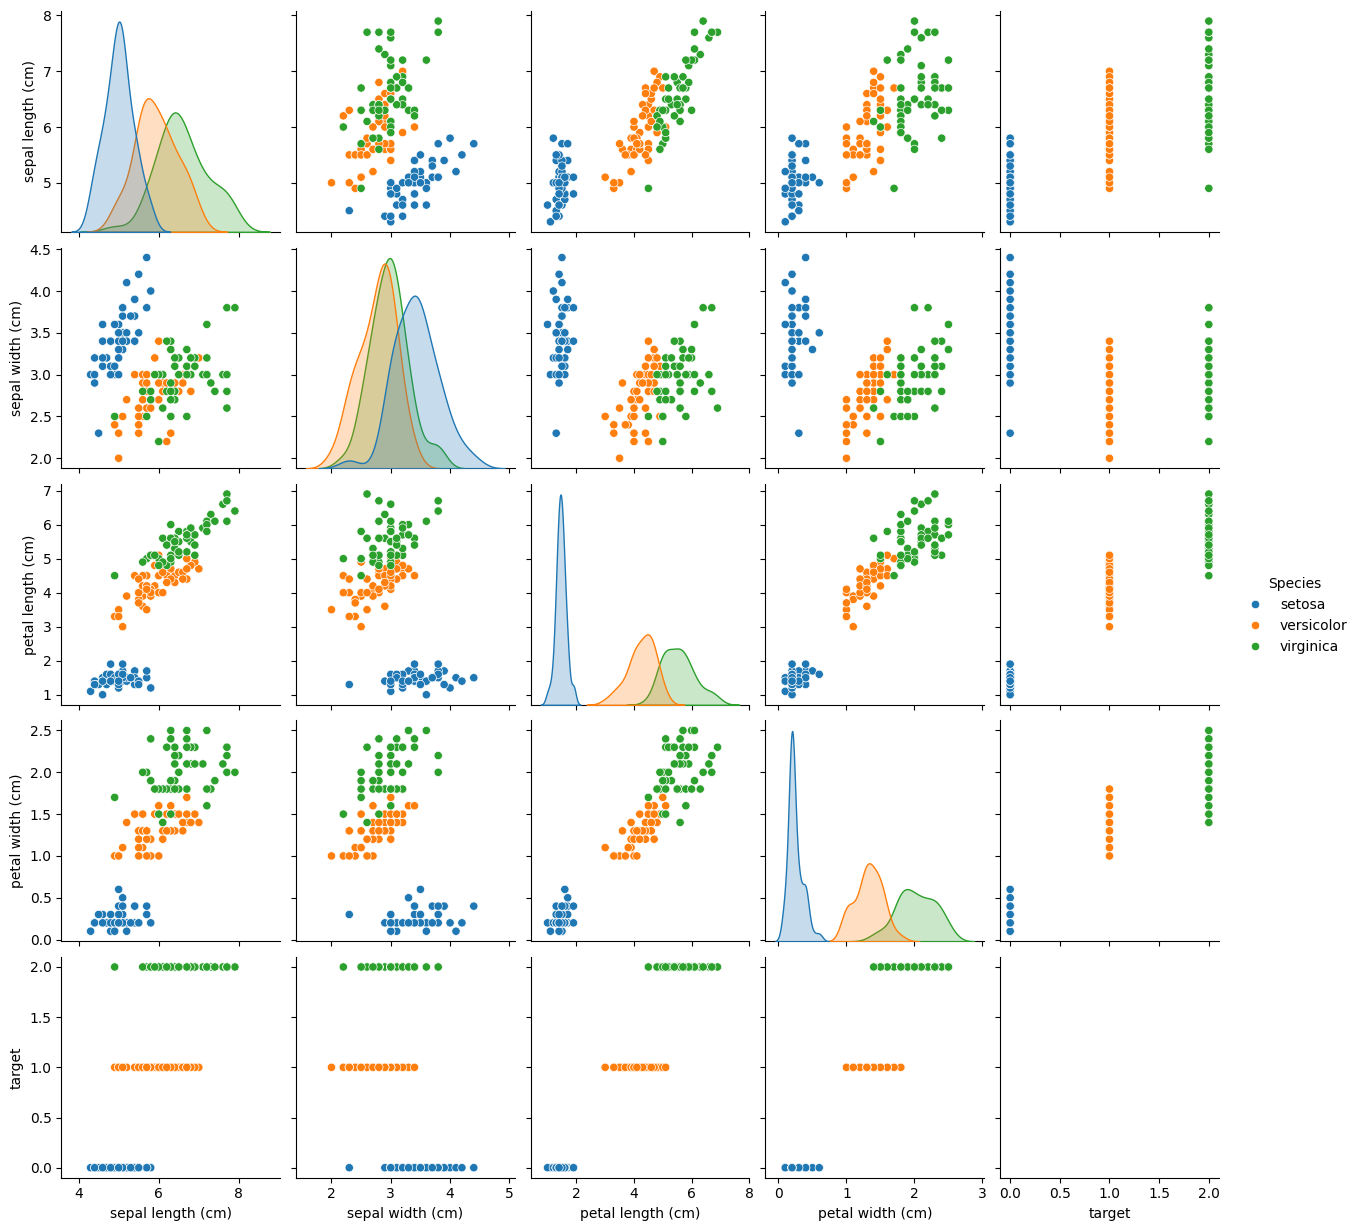

In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, GridSearchCV
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import accuracy_score,f1_score,recall_score,precision_score,confusion_matrix,classification_report
from sklearn.datasets import load_iris

import pandas as pd

# Load the dataset
iris = load_iris()

# Create a DataFrame
df = pd.DataFrame(data=iris.data, columns=iris.feature_names)
df['target'] = iris.target

# Map numerical target to species names for hue in pairplot
df['Species'] = df['target'].map(lambda x: iris.target_names[x])

# Display the DataFrame and the first 5 rows
print(df.head())

#sns.pairplot(data = df, hue = 'Species')

X_train, X_test, y_train, y_test = train_test_split(df.drop(['target', 'Species'], axis=1), df['Species'], random_state = 18, test_size=0.2)
param={
    'kernel':('linear','poly','rbf','sigmoid'),
    'degree':(3,4,5),
    'gamma':('scale','auto'),
    'decision_function_shape':('ovo','ovr')
}
svc = SVC()
gv = GridSearchCV(estimator=svc,param_grid=param)
gv.fit(X_train,y_train)
print(gv.best_params_)
print(gv.best_score_)
print(gv.best_estimator_)

prediction = gv.predict(X_test)
accuracy = accuracy_score(y_test, prediction)


print(f'Accuracy: {accuracy:.4f}')